# Valutazione strict vs lenient delle predizioni out-of-fold

Questo notebook legge i due file BIO multi-colonna (`oof_gold_bio.tsv`, `oof_pred_bio.tsv`),
ricostruisce gli span e calcola **P, R e F1** in tre modalità:

| Modalità | Una predizione è corretta se… |
|---|---|
| **strict** | inizio, fine ed etichetta coincidono esattamente |
| **lenient** | si sovrappone di almeno un token a uno span gold con la stessa etichetta |
| **partial** | come lenient, ma un match non esatto vale 0.5 (schema SemEval-2013) |

Gli abbinamenti sono sempre **1-a-1**: uno span gold può essere "coperto" da una sola predizione e viceversa.

Poi analizza **che tipo di errori** fa il modello (confini sbagliati, etichetta sbagliata, span mancati o inventati)
e mostra tutto in grafici.

> **Nota:** i file OOF non contengono il numero di fold, quindi tutte le metriche sono *pooled*
> (conteggi sommati su tutti i fold). Al posto della deviazione standard tra fold il notebook calcola
> **intervalli di confidenza bootstrap** ricampionando le frasi.

## 0. Configurazione

In [14]:
import re
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- percorsi: modifica se i file sono altrove ---
GOLD_PATH = Path("oof.gold.bio.tsv")
PRED_PATH = Path("oof.pred.bio.tsv")
CV_SUMMARY_PATH = Path("cv_summary.tsv")   # opzionale: serve solo per il controllo di coerenza
OUT_DIR = Path("risultati_lenient")
OUT_DIR.mkdir(exist_ok=True)

N_BOOTSTRAP = 1000      # ricampionamenti per gli intervalli di confidenza
SEED = 42

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Lettura dei file BIO

Struttura dei file: una riga per token, una colonna per ogni frame, righe vuote tra una frase e l'altra.
Una cella può contenere più tag separati da `|` quando sullo stesso token ci sono più span dello stesso frame
(per esempio `B-DESCR_Neutral|B-DESCR_Positive`, oppure `I-FOOD_LU|B-FOOD_LU` per uno span annidato in un altro).

Nel gold ci sono alcuni tag malformati (`B_CURE_LU`, `o`, `BO`, `i-…`, celle vuote…).
Vengono trattati come `O`, che è anche la scelta con cui sono stati prodotti i numeri di `cv_summary.tsv`
(lo verifichiamo al passo 3). La cella qui sotto li elenca, così puoi decidere se correggerli alla fonte.

In [15]:
TAG_VALIDO = re.compile(r"^[BI]-\S+$")

def leggi_bio(path):
    # Ritorna (lista dei frame, lista di frasi); ogni frase è una lista di righe [token, tag_frame1, ...]
    frasi, cur = [], []
    with open(path, encoding="utf-8") as f:
        frames = f.readline().rstrip("\n").split("\t")[1:]
        for line in f:
            line = line.rstrip("\n")
            if not line.strip():
                if cur:
                    frasi.append(cur)
                    cur = []
                continue
            cur.append(line.split("\t"))
    if cur:
        frasi.append(cur)
    return frames, frasi


def tag_anomali(frames, frasi, nome):
    righe = []
    for si, s in enumerate(frasi):
        for ti, row in enumerate(s):
            for fi, fr in enumerate(frames):
                for t in row[fi + 1].split("|"):
                    if t != "O" and not TAG_VALIDO.match(t):
                        righe.append(dict(file=nome, frase=si, pos=ti, token=row[0], frame=fr, tag=repr(t)))
    return pd.DataFrame(righe)


FRAMES, gold_frasi = leggi_bio(GOLD_PATH)
frames_p, pred_frasi = leggi_bio(PRED_PATH)

assert FRAMES == frames_p, "I due file hanno colonne diverse"
assert len(gold_frasi) == len(pred_frasi), "Numero di frasi diverso"
for g, p in zip(gold_frasi, pred_frasi):
    assert [r[0] for r in g] == [r[0] for r in p], "Token non allineati"

print(f"Frame: {FRAMES}")
print(f"Frasi: {len(gold_frasi)}   Token: {sum(len(s) for s in gold_frasi)}")

anomali = pd.concat([tag_anomali(FRAMES, gold_frasi, "gold"),
                     tag_anomali(FRAMES, pred_frasi, "pred")], ignore_index=True)
print(f"\nTag malformati (trattati come O): {len(anomali)}")
anomali

Frame: ['FOOD_ENTITY', 'FOOD_ATTRIBUTES', 'DESCRIPTOR', 'COOKING_CREATION', 'PRESERVING', 'CURE']
Frasi: 810   Token: 44227

Tag malformati (trattati come O): 28


,file,frase,pos,token,frame,tag
0,gold,19,15,oranges,COOKING_CREATION,'O-COOKING_CREATION_Food_Material'
1,gold,343,8,useful,CURE,'B_CURE_LU'
2,gold,357,3,invaluable,CURE,'B_CURE_LU'
3,gold,416,15,applied,CURE,'B_CURE_LU'
4,gold,439,5,substances,FOOD_ENTITY,'B_FOOD_LU'
5,gold,442,13,articles,FOOD_ENTITY,'I_FOOD_LU'
6,gold,457,29,essences,FOOD_ATTRIBUTES,'BO'
7,gold,457,33,poultry,PRESERVING,'Ot'
8,gold,520,8,in,CURE,'Os'
9,gold,527,273,pain,CURE,'B_CURE_Affliction'


## 2. Dai tag BIO agli span

Per ogni frase e ogni frame, i tag vengono letti token per token, **separatamente per etichetta**:

- `B-X` apre un nuovo span di tipo X;
- `I-X` continua uno span X aperto al token precedente (se ce ne sono più di uno aperti, continua il più lungo);
- `I-X` senza uno span X aperto (tag "orfano") apre comunque un nuovo span, come fa `conlleval`;
- uno span si chiude quando al token successivo non c'è più un `I-X` che lo continui.

Contare i tag per etichetta (e non solo guardarne la presenza) permette di gestire gli span annidati
dello stesso tipo, per esempio *Crab Apple* e *Apple* entrambi `FOOD_LU`.

Ogni span è `(frase, frame, etichetta, inizio, fine)` con `fine` esclusa.

In [16]:
def normalizza(tag):
    tag = tag.strip()
    return tag if TAG_VALIDO.match(tag) else "O"


def estrai_span(frames, frasi):
    span = []
    for si, s in enumerate(frasi):
        righe = s + [[None] + ["O"] * len(frames)]      # riga fittizia per chiudere gli span aperti
        for fi, fr in enumerate(frames):
            aperti = defaultdict(list)                   # etichetta -> lista di inizi, dal più vecchio
            for ti, row in enumerate(righe):
                n_I, n_B = Counter(), Counter()
                for t in (normalizza(x) for x in row[fi + 1].split("|")):
                    if t == "O":
                        continue
                    pref, lab = t.split("-", 1)
                    (n_I if pref == "I" else n_B)[lab] += 1
                nuovi = defaultdict(list)
                for lab, inizi in aperti.items():
                    k = min(n_I[lab], len(inizi))
                    nuovi[lab] += inizi[:k]                    # continuano
                    for st in inizi[k:]:                       # si chiudono
                        span.append((si, fr, lab, st, ti))
                    n_I[lab] -= k
                for lab, c in n_I.items():                     # I- orfani
                    nuovi[lab] += [ti] * c
                for lab, c in n_B.items():                     # B-
                    nuovi[lab] += [ti] * c
                aperti = nuovi
    df = pd.DataFrame(span, columns=["frase", "frame", "label", "start", "end"])
    df["testo"] = [" ".join(r[0] for r in frasi[s][a:b]) for s, a, b in zip(df.frase, df.start, df.end)]
    return df


gold = estrai_span(FRAMES, gold_frasi)
pred = estrai_span(FRAMES, pred_frasi)

# ordine delle etichette: per frame, nell'ordine di prima apparizione nel gold
LABELS = list(dict.fromkeys(gold.sort_values(["frame"], key=lambda s: s.map(FRAMES.index), kind="stable")["label"]))
LABEL2FRAME = dict(zip(gold.label, gold.frame))
print(f"Span gold: {len(gold)}   Span predetti: {len(pred)}   Etichette: {len(LABELS)}")
gold.head()

Span gold: 14190   Span predetti: 14688   Etichette: 19


,frase,frame,label,start,end,testo
0,0,FOOD_ENTITY,FOOD_LU,2,3,ORANGES
1,0,FOOD_ENTITY,FOOD_LU,4,5,LEMONS
2,0,FOOD_ENTITY,FOOD_LU,11,12,oranges
3,0,FOOD_ENTITY,FOOD_LU,34,35,water
4,0,FOOD_ENTITY,FOOD_LU,82,83,orange


## 3. Abbinamento gold ↔ predizioni

Per ogni gruppo *(frase, frame, etichetta)*:

1. si abbinano prima gli span **identici** (match esatti);
2. tra quelli rimasti si abbinano gli span che **si sovrappongono**, partendo dalla sovrapposizione maggiore,
   senza riusare uno span già abbinato (match parziali).

Il risultato è una tabella di conteggi per gruppo: `n_gold`, `n_pred`, `esatti`, `parziali`.
Da questi conteggi derivano tutte le metriche:

- **strict**: TP = esatti
- **lenient**: TP = esatti + parziali
- **partial**: TP = esatti + 0.5 × parziali

e in tutti i casi P = TP / n_pred, R = TP / n_gold.

In [17]:
def sovrapposizione(a, b):
    return max(0, min(a[1], b[1]) - max(a[0], b[0]))


def abbina(g_span, p_span):
    # g_span, p_span: liste di (start, end). Ritorna (esatti, parziali, coppie_parziali)
    g_lib, p_lib = list(range(len(g_span))), list(range(len(p_span)))
    esatti = 0
    for i in list(g_lib):
        for j in p_lib:
            if g_span[i] == p_span[j]:
                g_lib.remove(i); p_lib.remove(j); esatti += 1
                break
    cand = sorted(((sovrapposizione(g_span[i], p_span[j]), i, j)
                   for i in g_lib for j in p_lib if sovrapposizione(g_span[i], p_span[j]) > 0),
                  reverse=True)
    coppie = []
    for _, i, j in cand:
        if i in g_lib and j in p_lib:
            g_lib.remove(i); p_lib.remove(j)
            coppie.append((g_span[i], p_span[j]))
    return esatti, len(coppie), coppie


chiavi = ["frase", "frame", "label"]
g_grp = gold.groupby(chiavi)[["start", "end"]].apply(lambda d: list(zip(d.start, d.end)))
p_grp = pred.groupby(chiavi)[["start", "end"]].apply(lambda d: list(zip(d.start, d.end)))

righe, esempi_confine = [], []
for k in g_grp.index.union(p_grp.index):
    gs = g_grp.get(k, [])
    ps = p_grp.get(k, [])
    e, p, coppie = abbina(gs, ps)
    righe.append((*k, len(gs), len(ps), e, p))
    for (ga, gb), (pa, pb) in coppie:
        toks = [r[0] for r in gold_frasi[k[0]]]
        esempi_confine.append(dict(frase=k[0], frame=k[1], label=k[2],
                                   gold=" ".join(toks[ga:gb]), pred=" ".join(toks[pa:pb]),
                                   tipo=("pred più lungo" if pa <= ga and pb >= gb else
                                         "pred più corto" if pa >= ga and pb <= gb else "spostato")))

conteggi = pd.DataFrame(righe, columns=chiavi + ["n_gold", "n_pred", "esatti", "parziali"])
esempi_confine = pd.DataFrame(esempi_confine)
conteggi.head()

,frase,frame,label,n_gold,n_pred,esatti,parziali
0,0,COOKING_CREATION,COOKING_CREATION_Food_Material,7,8,5,1
1,0,COOKING_CREATION,COOKING_CREATION_LU,14,11,9,0
2,0,DESCRIPTOR,DESCR_Neutral,8,7,7,0
3,0,DESCRIPTOR,DESCR_Positive,1,0,0,0
4,0,FOOD_ATTRIBUTES,FOOD_Constituent_Part,3,1,1,0


### Controllo di coerenza con `cv_summary.tsv`

Il TP strict che calcoliamo qui deve coincidere con i `tp`, `fp`, `fn` del file di riepilogo.
Se coincide, la ricostruzione degli span è identica a quella usata nella valutazione originale
e il lenient è confrontabile direttamente.

In [18]:
if CV_SUMMARY_PATH.exists():
    cv = pd.read_csv(CV_SUMMARY_PATH, sep="\t")
    cv = cv[~cv["label"].str.startswith("<")].set_index("label")
    tot = conteggi.groupby("label")[["n_gold", "n_pred", "esatti"]].sum()
    chk = pd.DataFrame({
        "gold (qui)": tot.n_gold, "gold (cv)": cv.gold_spans,
        "tp (qui)": tot.esatti, "tp (cv)": cv.tp,
        "fp (qui)": tot.n_pred - tot.esatti, "fp (cv)": cv.fp,
    }).reindex(LABELS)
    diff = (chk["gold (qui)"] != chk["gold (cv)"]) | (chk["tp (qui)"] != chk["tp (cv)"]) | (chk["fp (qui)"] != chk["fp (cv)"])
    print("✅ Conteggi strict identici a cv_summary.tsv" if not diff.any()
          else f"⚠️ Differenze su {diff.sum()} etichette:")
    display(chk[diff] if diff.any() else chk)
else:
    print("cv_summary.tsv non trovato: controllo saltato")

✅ Conteggi strict identici a cv_summary.tsv


,gold (qui),gold (cv),tp (qui),tp (cv),fp (qui),fp (cv)
label,,,,,,
FOOD_LU,3378,3378.0,3026,3026.0,427,427.0
FOOD_Unit,473,473.0,361,361.0,150,150.0
FOOD_Constituent_Part,451,451.0,335,335.0,143,143.0
FOOD_Count,463,463.0,361,361.0,159,159.0
DESCR_Neutral,1198,1198.0,915,915.0,442,442.0
DESCR_Positive,361,361.0,179,179.0,234,234.0
DESCR_Negative,53,53.0,0,0.0,1,1.0
COOKING_CREATION_Food_Material,953,953.0,549,549.0,422,422.0
COOKING_CREATION_LU,999,999.0,818,818.0,230,230.0


## 4. Metriche strict / lenient / partial

Calcoliamo P, R, F1 nelle tre modalità a tre livelli:

- per **etichetta**;
- per **frame** (micro: conteggi sommati sulle etichette del frame);
- **globale**: micro su tutto e **macro** (media semplice degli F1 delle etichette).

In [19]:
MODES = ["strict", "partial", "lenient"]


def prf(n_gold, n_pred, esatti, parziali, mode):
    tp = esatti + {"strict": 0, "partial": 0.5, "lenient": 1}[mode] * parziali
    p = np.divide(tp, n_pred, out=np.zeros_like(tp, dtype=float), where=np.asarray(n_pred) > 0)
    r = np.divide(tp, n_gold, out=np.zeros_like(tp, dtype=float), where=np.asarray(n_gold) > 0)
    f = np.divide(2 * p * r, p + r, out=np.zeros_like(p, dtype=float), where=(p + r) > 0)
    return p, r, f


def tabella_metriche(agg):
    out = agg.copy()
    for m in MODES:
        p, r, f = prf(agg.n_gold.values.astype(float), agg.n_pred.values.astype(float),
                      agg.esatti.values.astype(float), agg.parziali.values.astype(float), m)
        out[f"P_{m}"], out[f"R_{m}"], out[f"F1_{m}"] = p, r, f
    return out


cols = ["n_gold", "n_pred", "esatti", "parziali"]
per_label = tabella_metriche(conteggi.groupby("label")[cols].sum()).reindex(LABELS)
per_label.insert(0, "frame", per_label.index.map(LABEL2FRAME))

per_frame = tabella_metriche(conteggi.groupby("frame")[cols].sum()).reindex(FRAMES)
globale = tabella_metriche(conteggi[cols].sum().to_frame("<micro>").T)
macro = pd.DataFrame({f"F1_{m}": [per_label[f"F1_{m}"].mean()] for m in MODES}, index=["<macro>"])

# tabella unica nello stesso stile di cv_summary.tsv
riepilogo = pd.concat([
    per_label.reset_index(),
    per_frame.reset_index().rename(columns={"index": "frame"}).assign(label="<micro>"),
    globale.assign(frame="<ALL>").reset_index(names="label"),
    macro.assign(frame="<ALL>").reset_index(names="label"),
], ignore_index=True)
riepilogo = riepilogo[["frame", "label"] + cols + [f"{x}_{m}" for m in MODES for x in "P R F1".split()]]
riepilogo.to_csv(OUT_DIR / "cv_summary_lenient.tsv", sep="\t", index=False, float_format="%.4f")

vista = ["frame", "label", "n_gold", "F1_strict", "F1_partial", "F1_lenient"]
riepilogo[vista].assign(guadagno=riepilogo.F1_lenient - riepilogo.F1_strict).round(3)

,frame,label,n_gold,F1_strict,F1_partial,F1_lenient,guadagno
0,FOOD_ENTITY,FOOD_LU,3378.0,0.886,0.911,0.935,0.049
1,FOOD_ATTRIBUTES,FOOD_Unit,473.0,0.734,0.782,0.829,0.096
2,FOOD_ATTRIBUTES,FOOD_Constituent_Part,451.0,0.721,0.744,0.766,0.045
3,FOOD_ATTRIBUTES,FOOD_Count,463.0,0.734,0.779,0.824,0.090
4,DESCRIPTOR,DESCR_Neutral,1198.0,0.716,0.741,0.766,0.050
5,DESCRIPTOR,DESCR_Positive,361.0,0.463,0.526,0.589,0.127
6,DESCRIPTOR,DESCR_Negative,53.0,0.000,0.000,0.000,0.000
7,COOKING_CREATION,COOKING_CREATION_Food_Material,953.0,0.571,0.612,0.653,0.082
8,COOKING_CREATION,COOKING_CREATION_LU,999.0,0.799,0.822,0.845,0.046
9,COOKING_CREATION,COOKING_CREATION_Food_Product,139.0,0.267,0.299,0.332,0.064


### Intervalli di confidenza bootstrap

Non avendo i fold, stimiamo l'incertezza ricampionando **le frasi** con reinserimento
(le frasi, non gli span, perché gli span della stessa frase non sono indipendenti).
Per ogni ricampionamento ricalcoliamo le metriche; l'intervallo al 95% è tra il 2.5° e il 97.5° percentile.

In [20]:
rng = np.random.default_rng(SEED)
n_frasi = len(gold_frasi)

# matrice frasi × etichette per ciascun conteggio: il bootstrap diventa una somma pesata
mat = {c: conteggi.pivot_table(index="frase", columns="label", values=c, aggfunc="sum", fill_value=0)
              .reindex(index=range(n_frasi), columns=LABELS, fill_value=0).values.astype(float)
       for c in cols}

pesi = rng.multinomial(n_frasi, np.full(n_frasi, 1 / n_frasi), size=N_BOOTSTRAP)   # (B, frasi)
boot = {c: pesi @ mat[c] for c in cols}                                             # (B, etichette)

ci = {}
for m in MODES:
    _, _, f_lab = prf(boot["n_gold"], boot["n_pred"], boot["esatti"], boot["parziali"], m)
    _, _, f_mic = prf(*(boot[c].sum(1) for c in cols), m)
    f_mac = f_lab.mean(1)
    ci[m] = pd.DataFrame(
        np.vstack([np.percentile(f_lab, [2.5, 97.5], axis=0).T,
                   np.percentile(f_mic, [2.5, 97.5])[None],
                   np.percentile(f_mac, [2.5, 97.5])[None]]),
        index=LABELS + ["<micro>", "<macro>"], columns=["lo", "hi"])

pd.concat({m: ci[m] for m in MODES}, axis=1).round(3)

strict        partial        lenient       
                                   lo     hi      lo     hi      lo     hi
FOOD_LU                         0.873  0.898   0.901  0.920   0.928  0.943
FOOD_Unit                       0.691  0.775   0.748  0.813   0.797  0.856
FOOD_Constituent_Part           0.679  0.761   0.704  0.778   0.731  0.800
FOOD_Count                      0.695  0.773   0.747  0.810   0.793  0.851
DESCR_Neutral                   0.692  0.738   0.720  0.761   0.746  0.785
DESCR_Positive                  0.406  0.516   0.479  0.572   0.546  0.634
DESCR_Negative                  0.000  0.000   0.000  0.000   0.000  0.000
COOKING_CREATION_Food_Material  0.539  0.599   0.582  0.638   0.621  0.681
COOKING_CREATION_LU             0.778  0.820   0.804  0.840   0.828  0.861
COOKING_CREATION_Food_Product   0.178  0.354   0.214  0.383   0.240  0.422
PR_LU                           0.818  0.868   0.839  0.882   0.857  0.897
PR_Food_Patient                 0.634  0.717   0.684  0.754   0.731  0.798
PR_Medium                       0.603  0.707   0.643  0.738   0.677  0.771
CURE_Food_Treatment             0.721  0.775   0.772  0.817   0.821  0.862
CURE_Affliction                 0.679  0.739   0.766  0.809   0.850  0.884
CURE_LU                         0.722  0.777   0.757  0.804   0.787  0.832
CURE_Patient                    0.483  0.632   0.596  0.707   0.686  0.796
CURE_Body_Part                  0.736  0.812   0.775  0.840   0.810  0.870
CURE_Healer                     0.000  0.387   0.238  0.563   0.400  0.812
<micro>                         0.739  0.757   0.777  0.793   0.815  0.831
<macro>                         0.606  0.637   0.656  0.683   0.703  0.731

## 5. Anatomia degli errori

Il lenient dice *quanto* si recupera ignorando i confini; qui vediamo *da dove* vengono gli errori.
Per ogni span **gold** cerchiamo la predizione dello stesso frame che gli somiglia di più e lo classifichiamo:

| Categoria | Significato |
|---|---|
| esatto | c'è una predizione identica (span ed etichetta) |
| confine sbagliato | etichetta giusta, ma confini diversi |
| etichetta sbagliata | stesso span, etichetta diversa dello stesso frame |
| etichetta + confine | sovrapposizione con un'etichetta diversa |
| mancato | nessuna predizione sovrapposta nel frame |

Questa classificazione guarda ogni span gold separatamente (non è 1-a-1), quindi serve per la diagnosi,
non per le metriche. Dalla stessa analisi ricaviamo una **matrice di confusione** tra etichette dello stesso frame.

In [21]:
CATEGORIE = ["esatto", "confine sbagliato", "etichetta sbagliata", "etichetta + confine", "mancato"]

pred_idx = defaultdict(list)
for r in pred.itertuples():
    pred_idx[(r.frase, r.frame)].append((r.start, r.end, r.label))

cat, lab_pred = [], []
for r in gold.itertuples():
    best, best_lab = 4, None
    for a, b, l in pred_idx[(r.frase, r.frame)]:
        ov = sovrapposizione((r.start, r.end), (a, b))
        if ov == 0:
            continue
        same_span, same_lab = (a, b) == (r.start, r.end), l == r.label
        c = 0 if same_span and same_lab else 1 if same_lab else 2 if same_span else 3
        if c < best:
            best, best_lab = c, l
    cat.append(CATEGORIE[best])
    lab_pred.append(best_lab if best_lab else "(nessuna)")
gold["categoria"], gold["label_pred"] = cat, lab_pred

anatomia = pd.crosstab(gold.label, gold.categoria).reindex(index=LABELS, columns=CATEGORIE, fill_value=0)

# lato predizioni: span predetti che non toccano nessuno span gold dello stesso frame ("inventati")
gold_idx = defaultdict(list)
for r in gold.itertuples():
    gold_idx[(r.frase, r.frame)].append((r.start, r.end))
pred["inventato"] = [not any(sovrapposizione((r.start, r.end), g) for g in gold_idx[(r.frase, r.frame)])
                     for r in pred.itertuples()]
anatomia["inventati (pred)"] = pred.groupby("label")["inventato"].sum().reindex(LABELS).fillna(0).astype(int)
anatomia

categoria,esatto,confine sbagliato,etichetta sbagliata,etichetta + confine,mancato,inventati (pred)
label,,,,,,
FOOD_LU,3026,187,0,0,165,232
FOOD_Unit,361,50,16,10,36,56
FOOD_Constituent_Part,335,21,6,0,89,96
FOOD_Count,361,44,16,7,35,91
DESCR_Neutral,915,65,32,4,182,227
DESCR_Positive,179,49,72,4,57,108
DESCR_Negative,0,0,26,6,21,0
COOKING_CREATION_Food_Material,549,82,1,0,321,276
COOKING_CREATION_LU,818,47,3,0,131,166


## 6. Grafici

In [22]:
palette = plt.get_cmap("tab10")
FCOLOR = {f: palette(i) for i, f in enumerate(FRAMES)}
MCOLOR = {"strict": "#4C72B0", "partial": "#8C8C8C", "lenient": "#DD8452"}
short = lambda s: s.replace("COOKING_CREATION_", "CC_")
leg_frames = [Patch(color=FCOLOR[f], label=f) for f in FRAMES]

def salva(fig, nome):
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"{nome}.png", dpi=200, bbox_inches="tight")
    plt.show()

### 6.1 F1 strict → lenient per etichetta
Ogni riga va dal F1 strict (blu) al F1 lenient (arancione); il punto grigio è il partial.
Le barrette sono gli intervalli bootstrap al 95%. **Più lunga la linea, più errori di confine** su quell'etichetta.

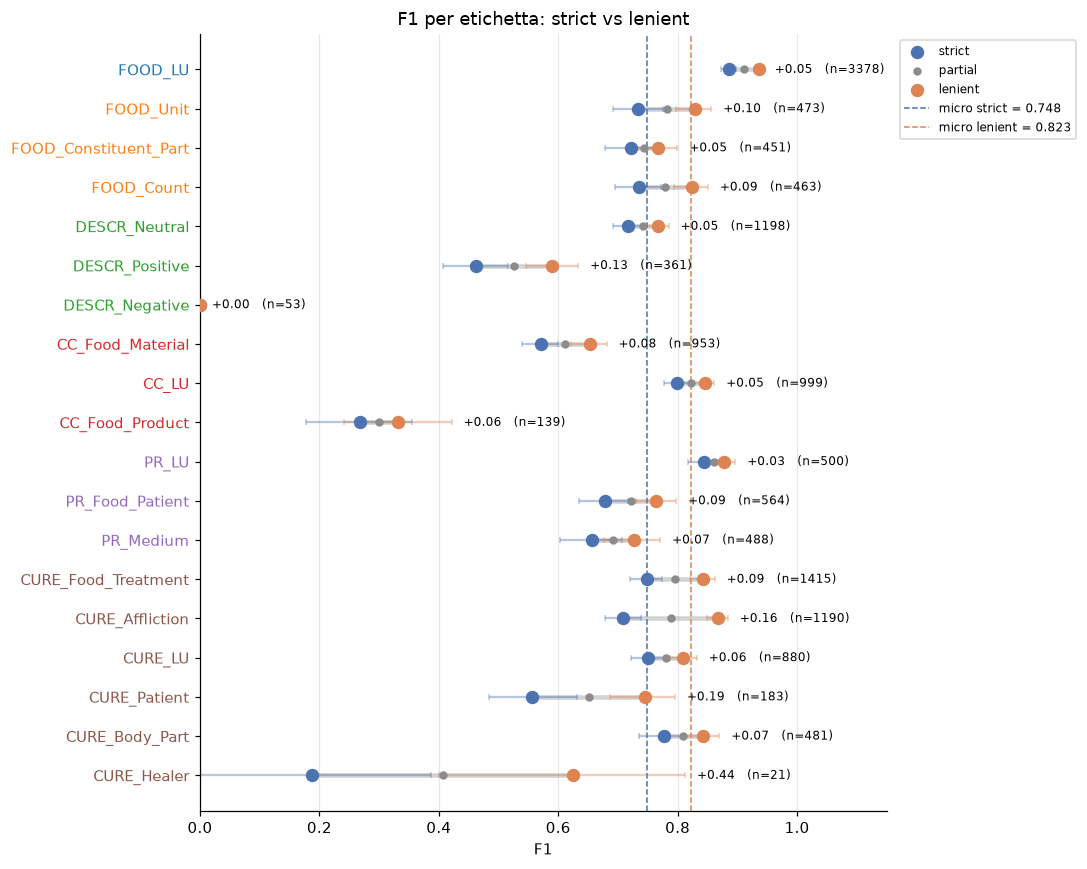

In [23]:
d = per_label.iloc[::-1]
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(10, 8))
ax.hlines(y, d.F1_strict, d.F1_lenient, color="lightgrey", lw=3, zorder=1)
for m, mk in [("strict", "o"), ("partial", "."), ("lenient", "o")]:
    lo, hi = ci[m].loc[d.index, "lo"], ci[m].loc[d.index, "hi"]
    if m != "partial":
        ax.errorbar(d[f"F1_{m}"], y, xerr=[d[f"F1_{m}"] - lo, hi - d[f"F1_{m}"]],
                    fmt="none", ecolor=MCOLOR[m], alpha=0.4, capsize=2)
    ax.scatter(d[f"F1_{m}"], y, color=MCOLOR[m], marker=mk, s=60 if m != "partial" else 80,
               zorder=3, label=m)
x_txt = np.maximum(ci["lenient"].loc[d.index, "hi"].values, ci["strict"].loc[d.index, "hi"].values)
for yi, (s, l, n, xt) in enumerate(zip(d.F1_strict, d.F1_lenient, d.n_gold, x_txt)):
    ax.text(xt + 0.02, yi, f"+{l - s:.2f}   (n={n})", va="center", fontsize=8)
ax.set_yticks(y, [short(l) for l in d.index])
for t, l in zip(ax.get_yticklabels(), d.index):
    t.set_color(FCOLOR[LABEL2FRAME[l]])
for m, ls in [("strict", "--"), ("lenient", "--")]:
    ax.axvline(globale[f"F1_{m}"].iloc[0], color=MCOLOR[m], ls=ls, lw=1,
               label=f"micro {m} = {globale[f'F1_{m}'].iloc[0]:.3f}")
ax.set_xlim(0, 1.15)
ax.set_xlabel("F1")
ax.set_title("F1 per etichetta: strict vs lenient")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
salva(fig, "01_strict_vs_lenient_etichette")

### 6.2 Confronto per frame
P, R e F1 micro per frame: barre piene = strict, barre tratteggiate sovrapposte = lenient.
La parte tratteggiata che sporge è ciò che si recupera correggendo solo i confini.

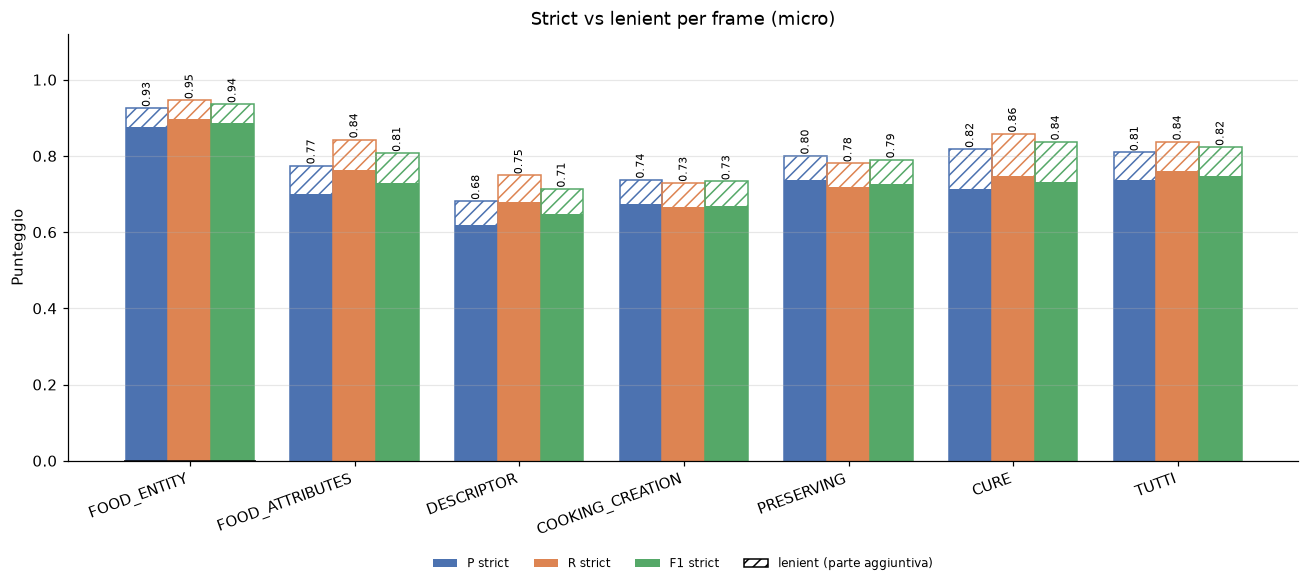

In [24]:
d = pd.concat([per_frame, globale.rename(index={"<micro>": "TUTTI"})])
x = np.arange(len(d))
w = 0.26
fig, ax = plt.subplots(figsize=(12, 5.5))
for k, (met, col) in enumerate([("P", "#4C72B0"), ("R", "#DD8452"), ("F1", "#55A868")]):
    xs = x + (k - 1) * w
    ax.bar(xs, d[f"{met}_lenient"], w, color="none", edgecolor=col, hatch="///", lw=1)
    ax.bar(xs, d[f"{met}_strict"], w, color=col, label=f"{met} strict")
    for xi, v in zip(xs, d[f"{met}_lenient"]):
        ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=7, rotation=90)
ax.bar(0, 0, color="none", edgecolor="k", hatch="///", label="lenient (parte aggiuntiva)")
ax.set_xticks(x, d.index, rotation=20, ha="right")
ax.set_ylim(0, 1.12)
ax.set_ylabel("Punteggio")
ax.set_title("Strict vs lenient per frame (micro)")
ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False)
salva(fig, "02_strict_vs_lenient_frame")

### 6.3 Precision vs Recall: spostamento da strict a lenient
Ogni freccia va dal punto strict al punto lenient della stessa etichetta.
Frecce lunghe = molti errori di confine; frecce corte = errori "veri" (span mancati o inventati).

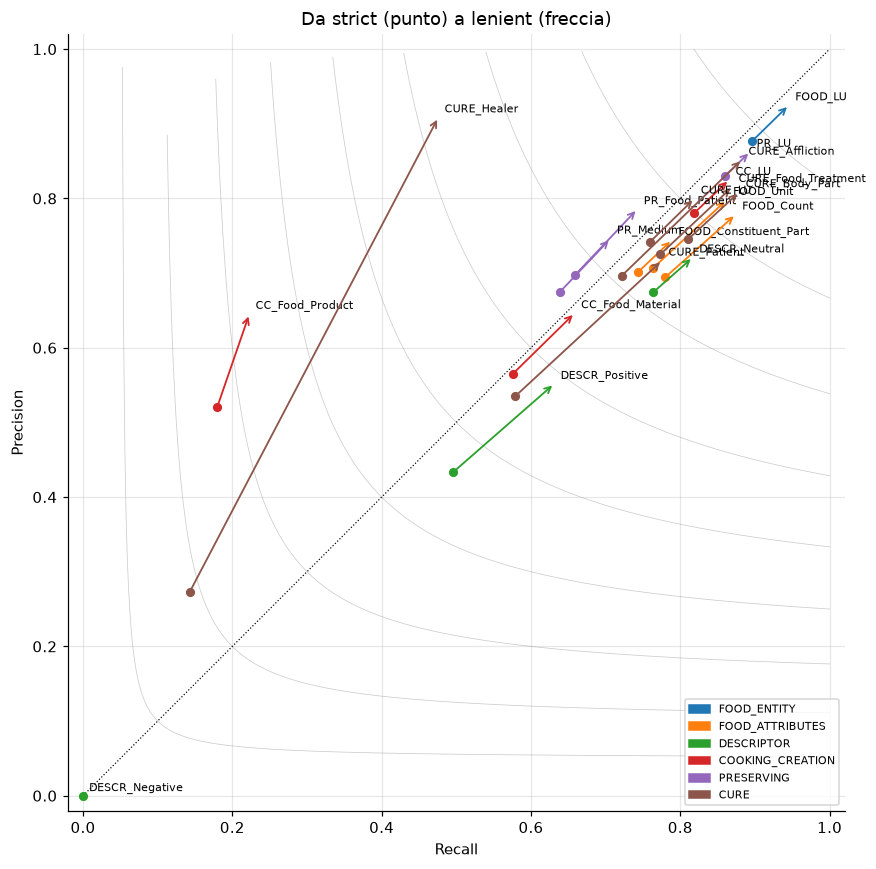

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 8))
r_ = np.linspace(0.001, 1, 600)
for f in np.arange(0.1, 1.0, 0.1):
    pp = f * r_ / (2 * r_ - f)
    msk = (r_ > f / 2) & (pp > 0) & (pp <= 1)
    ax.plot(r_[msk], pp[msk], c="grey", lw=0.5, alpha=0.4)
for lab, row in per_label.iterrows():
    col = FCOLOR[row.frame]
    ax.annotate("", xy=(row.R_lenient, row.P_lenient), xytext=(row.R_strict, row.P_strict),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.2))
    ax.scatter(row.R_strict, row.P_strict, color=col, s=25, zorder=3)
    ax.annotate(short(lab), (row.R_lenient, row.P_lenient), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.plot([0, 1], [0, 1], "k:", lw=0.8)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Da strict (punto) a lenient (freccia)")
ax.legend(handles=leg_frames, fontsize=7, loc="lower right")
salva(fig, "03_pr_spostamento")

### 6.4 Anatomia degli errori per etichetta
Composizione degli span gold per categoria (sinistra) e, per confronto, quanti span predetti sono
completamente inventati rispetto al totale delle predizioni (destra).

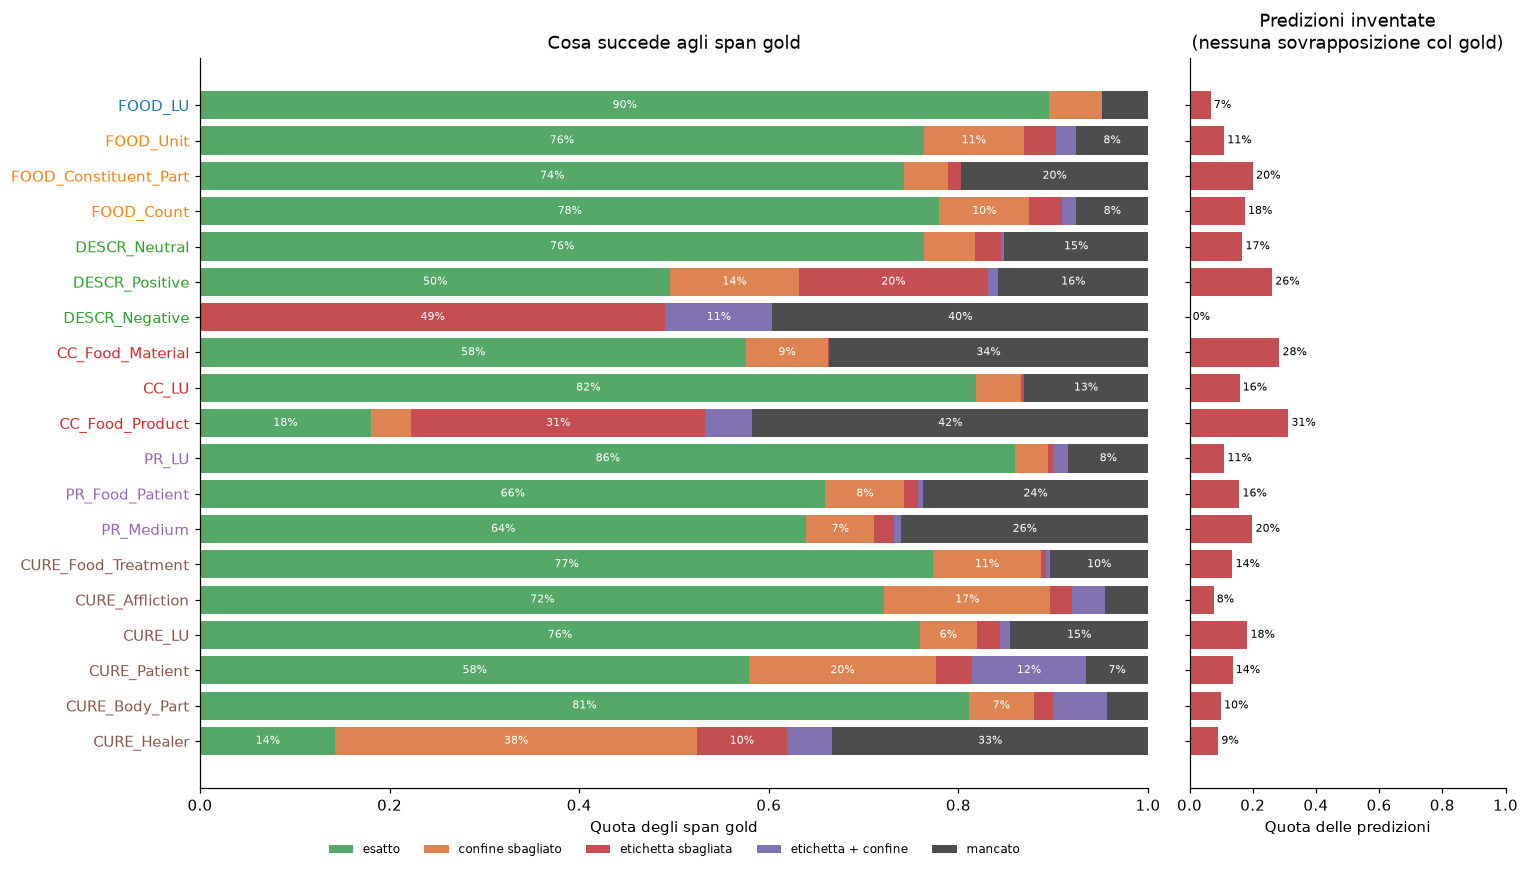

In [26]:
colori_cat = ["#55A868", "#DD8452", "#C44E52", "#8172B2", "#4d4d4d"]
d = anatomia[CATEGORIE].iloc[::-1]
frac = d.div(d.sum(axis=1), axis=0)
y = np.arange(len(d))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 8), sharey=True, gridspec_kw={"width_ratios": [3, 1]})
left = np.zeros(len(d))
for c, col in zip(CATEGORIE, colori_cat):
    ax.barh(y, frac[c], left=left, color=col, label=c)
    for yi, (l, v) in enumerate(zip(left, frac[c])):
        if v > 0.06:
            ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white")
    left += frac[c]
ax.set_yticks(y, [short(l) for l in d.index])
for t, l in zip(ax.get_yticklabels(), d.index):
    t.set_color(FCOLOR[LABEL2FRAME[l]])
ax.set_xlim(0, 1)
ax.set_xlabel("Quota degli span gold")
ax.set_title("Cosa succede agli span gold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=5, frameon=False, fontsize=8)
ax.grid(False)

inv = (anatomia["inventati (pred)"] / per_label.n_pred.replace(0, np.nan)).reindex(d.index).fillna(0)
ax2.barh(y, inv, color="#C44E52")
for yi, v in enumerate(inv):
    ax2.text(v + 0.01, yi, f"{v:.0%}", va="center", fontsize=7)
ax2.set_xlim(0, 1)
ax2.set_xlabel("Quota delle predizioni")
ax2.set_title("Predizioni inventate\n(nessuna sovrapposizione col gold)")
ax2.grid(False)
salva(fig, "04_anatomia_errori")

### 6.5 Confusione tra etichette dello stesso frame
Righe = etichetta gold, colonne = etichetta della predizione più simile (o *nessuna*).
Valori normalizzati per riga: la diagonale è la quota riconosciuta con l'etichetta giusta
(anche con confini imprecisi), il resto mostra con cosa viene scambiata.

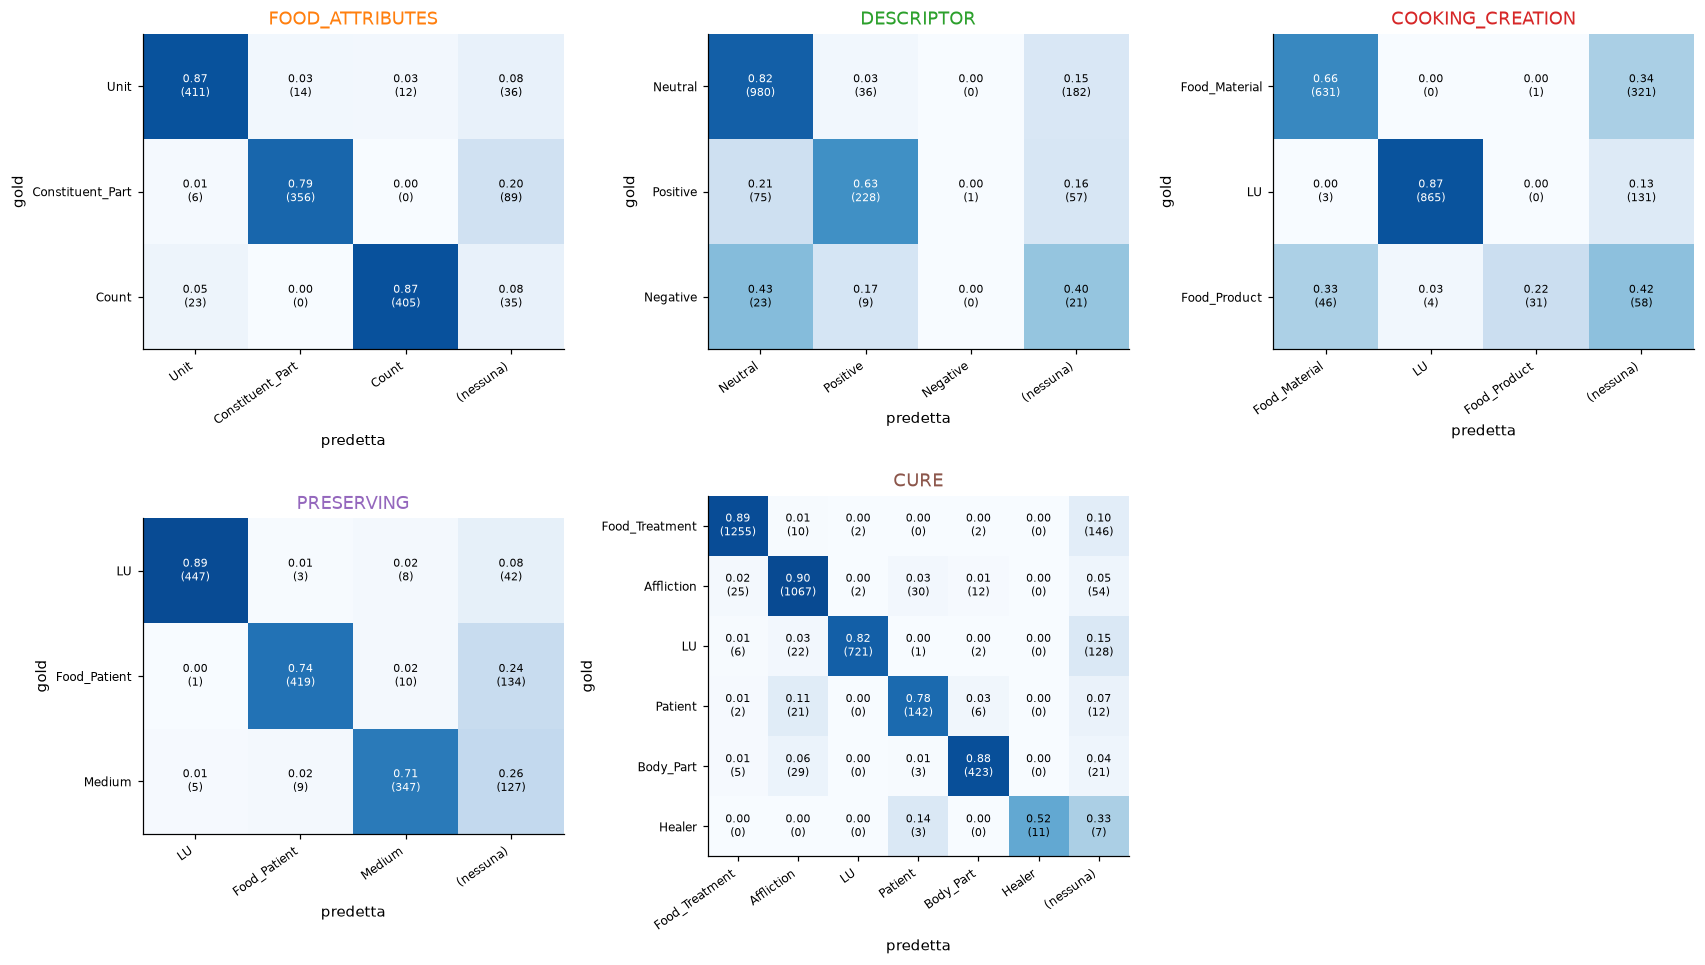

In [27]:
multi = [f for f in FRAMES if gold.loc[gold.frame == f, "label"].nunique() > 1]
ncol = 3
nrow = int(np.ceil(len(multi) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 4.6 * nrow))
for ax, fr in zip(axes.flat, multi):
    g = gold[gold.frame == fr]
    labs = [l for l in LABELS if LABEL2FRAME[l] == fr]
    cm = pd.crosstab(g.label, g.label_pred).reindex(index=labs, columns=labs + ["(nessuna)"], fill_value=0)
    cmn = cm.div(cm.sum(axis=1), axis=0)
    ax.imshow(cmn.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(cmn.shape[0]):
        for j in range(cmn.shape[1]):
            v = cmn.values[i, j]
            ax.text(j, i, f"{v:.2f}\n({cm.values[i, j]})", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.55 else "black")
    strip = lambda s: short(s).split("_", 1)[-1] if s != "(nessuna)" else s
    ax.set_xticks(range(cmn.shape[1]), [strip(c) for c in cmn.columns], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(cmn.shape[0]), [strip(c) for c in cmn.index], fontsize=8)
    ax.set_xlabel("predetta"); ax.set_ylabel("gold")
    ax.set_title(fr, color=FCOLOR[fr])
    ax.grid(False)
for ax in list(axes.flat)[len(multi):]:
    ax.axis("off")
salva(fig, "05_confusione_etichette")

## 7. Esempi di errori di confine
Un campione di match lenient che non sono esatti, per capire *come* sbaglia i confini il modello
(predizione troppo lunga, troppo corta o spostata). Cambia `ETICHETTA` per guardare un'etichetta specifica.

In [28]:
print("Tipo di errore di confine per etichetta (conteggi):")
display(pd.crosstab(esempi_confine.label, esempi_confine.tipo).reindex(LABELS).fillna(0).astype(int))

ETICHETTA = None          # es. "COOKING_CREATION_Food_Material"; None = tutte
N_ESEMPI = 20
e = esempi_confine if ETICHETTA is None else esempi_confine[esempi_confine.label == ETICHETTA]
e.sample(min(N_ESEMPI, len(e)), random_state=SEED)[["label", "tipo", "gold", "pred"]]

Tipo di errore di confine per etichetta (conteggi):


tipo,pred più corto,pred più lungo,spostato
label,,,
FOOD_LU,116,52,1
FOOD_Unit,25,21,1
FOOD_Constituent_Part,21,0,0
FOOD_Count,29,13,2
DESCR_Neutral,62,2,0
DESCR_Positive,49,0,0
DESCR_Negative,0,0,0
COOKING_CREATION_Food_Material,65,13,1
COOKING_CREATION_LU,39,7,1


,label,tipo,gold,pred
423,FOOD_LU,pred più corto,wine conserve,wine
548,CURE_Affliction,pred più lungo,all diseases,all diseases and hurts
731,COOKING_CREATION_Food_Material,pred più corto,same spiced vinegar,spiced vinegar
588,CURE_Food_Treatment,pred più lungo,juice of,juice of Lettuce
1052,FOOD_LU,pred più corto,horse mint,mint
616,DESCR_Positive,pred più corto,much more powerful,powerful
991,COOKING_CREATION_Food_Material,pred più corto,cramp bark,cramp
993,CURE_Food_Treatment,pred più lungo,high cranberry,high cranberry or
1072,FOOD_LU,pred più lungo,poultice,carrot poultice
923,COOKING_CREATION_Food_Material,pred più corto,orange peel,orange


## 8. Salvataggio

In [29]:
anatomia.to_csv(OUT_DIR / "anatomia_errori.tsv", sep="\t")
esempi_confine.to_csv(OUT_DIR / "errori_confine.tsv", sep="\t", index=False)
pd.concat({m: ci[m] for m in MODES}, axis=1).to_csv(OUT_DIR / "bootstrap_ci_f1.tsv", sep="\t")
print("File salvati in", OUT_DIR.resolve())
for f in sorted(OUT_DIR.iterdir()):
    print("  ", f.name)

File salvati in /Users/teresapaccosi/Desktop/food_trifecta_pipeline/multi_results /risultati_lenient
   01_strict_vs_lenient_etichette.png
   02_strict_vs_lenient_frame.png
   03_pr_spostamento.png
   04_anatomia_errori.png
   05_confusione_etichette.png
   anatomia_errori.tsv
   bootstrap_ci_f1.tsv
   cv_summary_lenient.tsv
   errori_confine.tsv
